In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Dataset URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

# Column Names
columns = [
    "mpg", "cylinders", "displacement",
    "horsepower", "weight", "acceleration",
    "model_year", "origin", "car_name"
]

# Load Dataset
df = pd.read_csv(
    url,
    sep=r"\s+",
    names=columns,
    na_values="?",
    quotechar='"'
)

# Display Dataset
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [3]:
# Select Input and Target
data = df[["displacement", "mpg"]].copy()

# Remove Missing Values
data = data.dropna()

# Check Dataset
print("Dataset Shape:", data.shape)

print("\nMissing Values:")
print(data.isnull().sum())

# Display First 5 Rows
data.head()

Dataset Shape: (398, 2)

Missing Values:
displacement    0
mpg             0
dtype: int64


,displacement,mpg
0,307.0,18.0
1,350.0,15.0
2,318.0,18.0
3,304.0,16.0
4,302.0,17.0


In [4]:
# Separate Input and Target
X = data[["displacement"]].values
y = data["mpg"].values

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Polynomial Features (Degree 2)
X_train_poly = np.column_stack([
    X_train[:, 0],
    X_train[:, 0] ** 2
])

X_test_poly = np.column_stack([
    X_test[:, 0],
    X_test[:, 0] ** 2
])

# Standardize Features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

# Add Bias Column
X_train_final = np.column_stack([
    np.ones(len(X_train_scaled)),
    X_train_scaled
])

X_test_final = np.column_stack([
    np.ones(len(X_test_scaled)),
    X_test_scaled
])

print("Training Data Shape:", X_train_final.shape)
print("Testing Data Shape:", X_test_final.shape)

Training Data Shape: (318, 3)
Testing Data Shape: (80, 3)


In [5]:
# Initialize Weights
theta = np.zeros(X_train_final.shape[1])

# Define Cost Function (MSE)
def compute_cost(X, y, theta):
    predictions = X @ theta
    errors = predictions - y
    return np.mean(errors ** 2)

# Define Gradient Function
def compute_gradient(X, y, theta):
    predictions = X @ theta
    errors = predictions - y
    gradient = (2 / len(y)) * (X.T @ errors)
    return gradient

print("Initial Weights:", theta)
print("Initial Cost:", compute_cost(X_train_final, y_train, theta))

Initial Weights: [0. 0. 0.]
Initial Cost: 620.0422012578616


In [6]:
# Initialize RMSProp Parameters
theta_rms = np.zeros(X_train_final.shape[1])

learning_rate = 0.05
beta = 0.9
epsilon = 1e-8
epochs = 1000

s = np.zeros_like(theta_rms)
rms_loss_history = []

# RMSProp Training
for epoch in range(epochs):

    # Calculate Gradient
    gradient = compute_gradient(
        X_train_final, y_train, theta_rms
    )

    # Moving Average of Squared Gradients
    s = beta * s + (1 - beta) * (gradient ** 2)

    # Update Weights
    theta_rms = theta_rms - (
        learning_rate * gradient / (np.sqrt(s) + epsilon)
    )

    # Calculate Loss
    loss = compute_cost(
        X_train_final, y_train, theta_rms
    )

    rms_loss_history.append(loss)

print("RMSProp Training Completed!")
print("Final Weights:", theta_rms)
print("Final Training MSE:", rms_loss_history[-1])

RMSProp Training Completed!
Final Weights: [ 23.6331761  -14.2431375    8.00020242]
Final Training MSE: 19.974557976406896


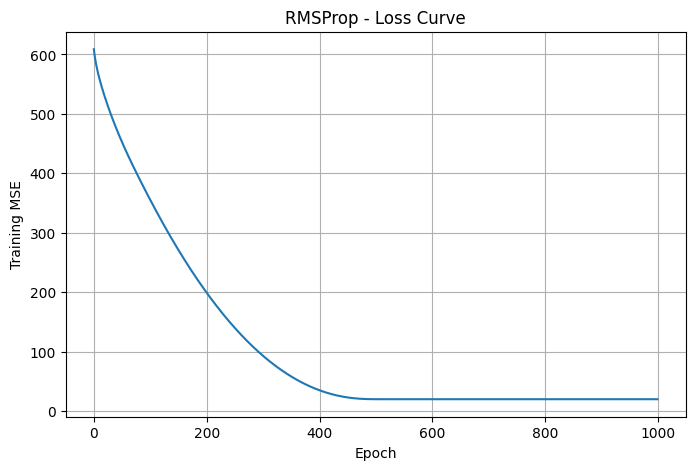

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(rms_loss_history)

plt.title("RMSProp - Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Training MSE")

plt.grid(True)
plt.show()

In [8]:
# Make Predictions
y_pred = X_test_final @ theta_rms

# Calculate Evaluation Metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("RMSProp Model Evaluation")
print("------------------------")
print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("Test R2 Score:", r2)

RMSProp Model Evaluation
------------------------
Test MSE: 15.15204431589434
Test RMSE: 3.892562692609374
Test R2 Score: 0.718187715997223


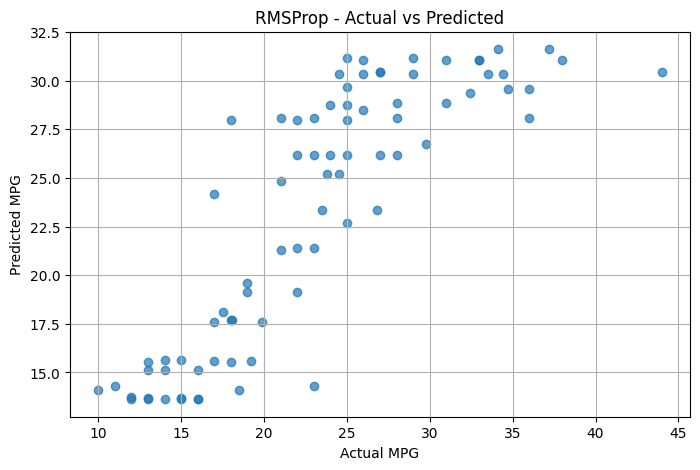

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("RMSProp - Actual vs Predicted")

plt.grid(True)
plt.show()